In [8]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Define Path
base_path = 'F:/Education/COLLEGE/PROGRAMING/Python/PROJECTS/PrachiNCUProject/Data'

class Silver:
    @staticmethod
    def Datacleansing(year, month, day):
        input_path = os.path.join(base_path, 'Bronze', year, month, day)
        csv_files = glob.glob(input_path + "/*.csv")
        if not csv_files:
            print(f"No CSV files found for {year}-{month}-{day}")
            return None

        df_list = []
        for file in csv_files:
            try:
                df = pd.read_csv(file)
                allowed_columns = [
                    'country', 'state', 'city', 'station', 'last_update', 
                    'pollutant_id', 'pollutant_min', 'pollutant_max', 
                    'pollutant_avg', 'longitude', 'latitude'
                ]
                if set(allowed_columns).issubset(df.columns):
                    file_date = pd.to_datetime(df['last_update'], format="%d-%m-%Y %H:%M:%S").dt.date.iloc[0]
                    if file_date == datetime(int(year), int(month), int(day)).date():
                        df_list.append(df)
            except Exception as e:
                print(f"Error processing file {file}: {e}")

        if not df_list:
            return None

        output_path = os.path.join(base_path, 'Silver', year, month, day)
        os.makedirs(output_path, exist_ok=True)

        combined_df = pd.concat(df_list, ignore_index=True)
        combined_df = combined_df.rename(columns={
            "country": "Country", "state": "State", "city": "City", 
            "station": "Station", "pollutant_id": "Pollutant_Type", 
            "pollutant_avg": "Pollutant_Avg", "pollutant_max": "Pollutant_Max",
            "longitude": "Longitude", "latitude": "Latitude"
        })
        combined_df["Date"] = pd.to_datetime(combined_df["last_update"], format="%d-%m-%Y %H:%M:%S").dt.date
        combined_df = combined_df.groupby([
            "Country", "State", "City", "Station", "Date", 
            "Pollutant_Type", "Longitude", "Latitude"
        ]).agg({"Pollutant_Avg": "mean", "Pollutant_Max": "max"}).reset_index()
        combined_df["Pollutant_Avg"] = combined_df["Pollutant_Avg"].round(2)
        combined_df["Pollutant_Max"] = combined_df["Pollutant_Max"].round(2)
        combined_df["Pollutant_Data"] = combined_df.apply(
            lambda row: row["Pollutant_Max"] if row["Pollutant_Type"] in ["OZONE1", "CO1"] else row["Pollutant_Avg"], axis=1
        )

        output_file_path = os.path.join(output_path, f'Silver_pollutiondata_{year}{month}{day}.csv')
        combined_df.to_csv(output_file_path, index=False)
        return combined_df

class Gold:
    @staticmethod
    def DataTransformation(year, month, day):
        input_path = os.path.join(base_path, 'Silver', year, month, day)
        csv_files = glob.glob(input_path + "/*.csv")
        if not csv_files:
            return None

        df_list = [pd.read_csv(file) for file in csv_files]
        combined_df = pd.concat(df_list, ignore_index=True)

        final_df = combined_df.pivot_table(
            index=["State", "City", "Station", "Date", "Longitude", "Latitude"],
            columns='Pollutant_Type', values='Pollutant_Data', fill_value=0
        ).reset_index()
        final_df["Checks"] = (final_df[["PM2.5", "PM10", "SO2", "NO2", "NH3", "CO", "OZONE"]] > 0).sum(axis=1)
        final_df["AQI"] = final_df[["PM2.5", "PM10", "SO2", "NO2", "NH3", "CO", "OZONE"]].max(axis=1)
        final_df.loc[final_df.Checks < 3, "AQI"] = np.NaN

        def get_AQI_bucket(x):
            if x <= 50: return "Good"
            elif x <= 100: return "Satisfactory"
            elif x <= 200: return "Moderate"
            elif x <= 300: return "Poor"
            elif x <= 400: return "Very Poor"
            else: return "Severe"

        final_df["AQI_Quality"] = final_df["AQI"].apply(get_AQI_bucket)
        final_df = final_df.dropna(subset=['AQI'])

        # Create output directory only if data is valid
        output_path = os.path.join(base_path, 'Gold', year, month, day)
        os.makedirs(output_path, exist_ok=True)

        output_file_path = os.path.join(output_path, f'Gold_pollutiondata_{year}{month}{day}.csv')
        final_df.to_csv(output_file_path, index=False)
        return final_df

class Platinum:
    @staticmethod
    def FinalData(year, month, day):
        input_path = os.path.join(base_path, 'Gold', year, month, day)
        csv_files = glob.glob(input_path + "/*.csv")
        if not csv_files:
            return None

        final_df = pd.concat((pd.read_csv(file) for file in csv_files), ignore_index=True)

        # Create output directory only if data is valid
        output_path = os.path.join(base_path, 'Platinum')
        os.makedirs(output_path, exist_ok=True)

        output_file_path = os.path.join(output_path, 'pollutiondata_Final.csv')
        final_df.to_csv(output_file_path, mode='a', index=False, header=not os.path.exists(output_file_path))
        return final_df

# Process All Dates from 2024
for year in range(2024, datetime.now().year + 1):
    for month in range(1, 13):
        for day in range(1, 32):
            try:
                year, month, day = str(year), f'{month}', f'{day}'
                print(f"Processing data for {year}-{month}-{day}")
                silver_data = Silver.Datacleansing(year, month, day)
                if silver_data is not None:
                    gold_data = Gold.DataTransformation(year, month, day)
                    if gold_data is not None:
                        platinum_data = Platinum.FinalData(year, month, day)
            except Exception as e:
                print(f"Error processing {year}-{month}-{day}: {e}")


Processing data for 2024-1-1
No CSV files found for 2024-1-1
Processing data for 2024-1-2
No CSV files found for 2024-1-2
Processing data for 2024-1-3
Processing data for 2024-1-4
Processing data for 2024-1-5
Processing data for 2024-1-6
Processing data for 2024-1-7
Processing data for 2024-1-8
Processing data for 2024-1-9
Processing data for 2024-1-10
Processing data for 2024-1-11
Processing data for 2024-1-12
Processing data for 2024-1-13
Processing data for 2024-1-14
No CSV files found for 2024-1-14
Processing data for 2024-1-15
No CSV files found for 2024-1-15
Processing data for 2024-1-16
No CSV files found for 2024-1-16
Processing data for 2024-1-17
No CSV files found for 2024-1-17
Processing data for 2024-1-18
Processing data for 2024-1-19
Processing data for 2024-1-20
Processing data for 2024-1-21
Processing data for 2024-1-22
Processing data for 2024-1-23
Processing data for 2024-1-24
Processing data for 2024-1-25
Processing data for 2024-1-26
Processing data for 2024-1-27
Pro


Summary Statistics:
                  PM2.5           PM10            SO2            NO2  \
count     173704.000000  173704.000000  173704.000000  173704.000000   
mean          82.178252      90.037408      14.626278      25.911196   
std           73.699859      60.726544      14.160639      23.995220   
min            0.000000       0.000000       0.000000       0.000000   
25%           33.830000      48.067500       5.570000      10.000000   
50%           59.600000      82.000000      11.000000      20.000000   
75%          106.400000     120.250000      19.000000      34.330000   
max          500.000000     475.000000     133.200000     432.750000   
skewness       1.681758       1.166766       2.463075       2.727752   
kurtosis       2.991953       2.418517       9.536461      15.739574   

                    NH3             CO          OZONE  
count     173704.000000  173704.000000  173704.000000  
mean           4.886309      35.037916      33.981178  
std            5.2

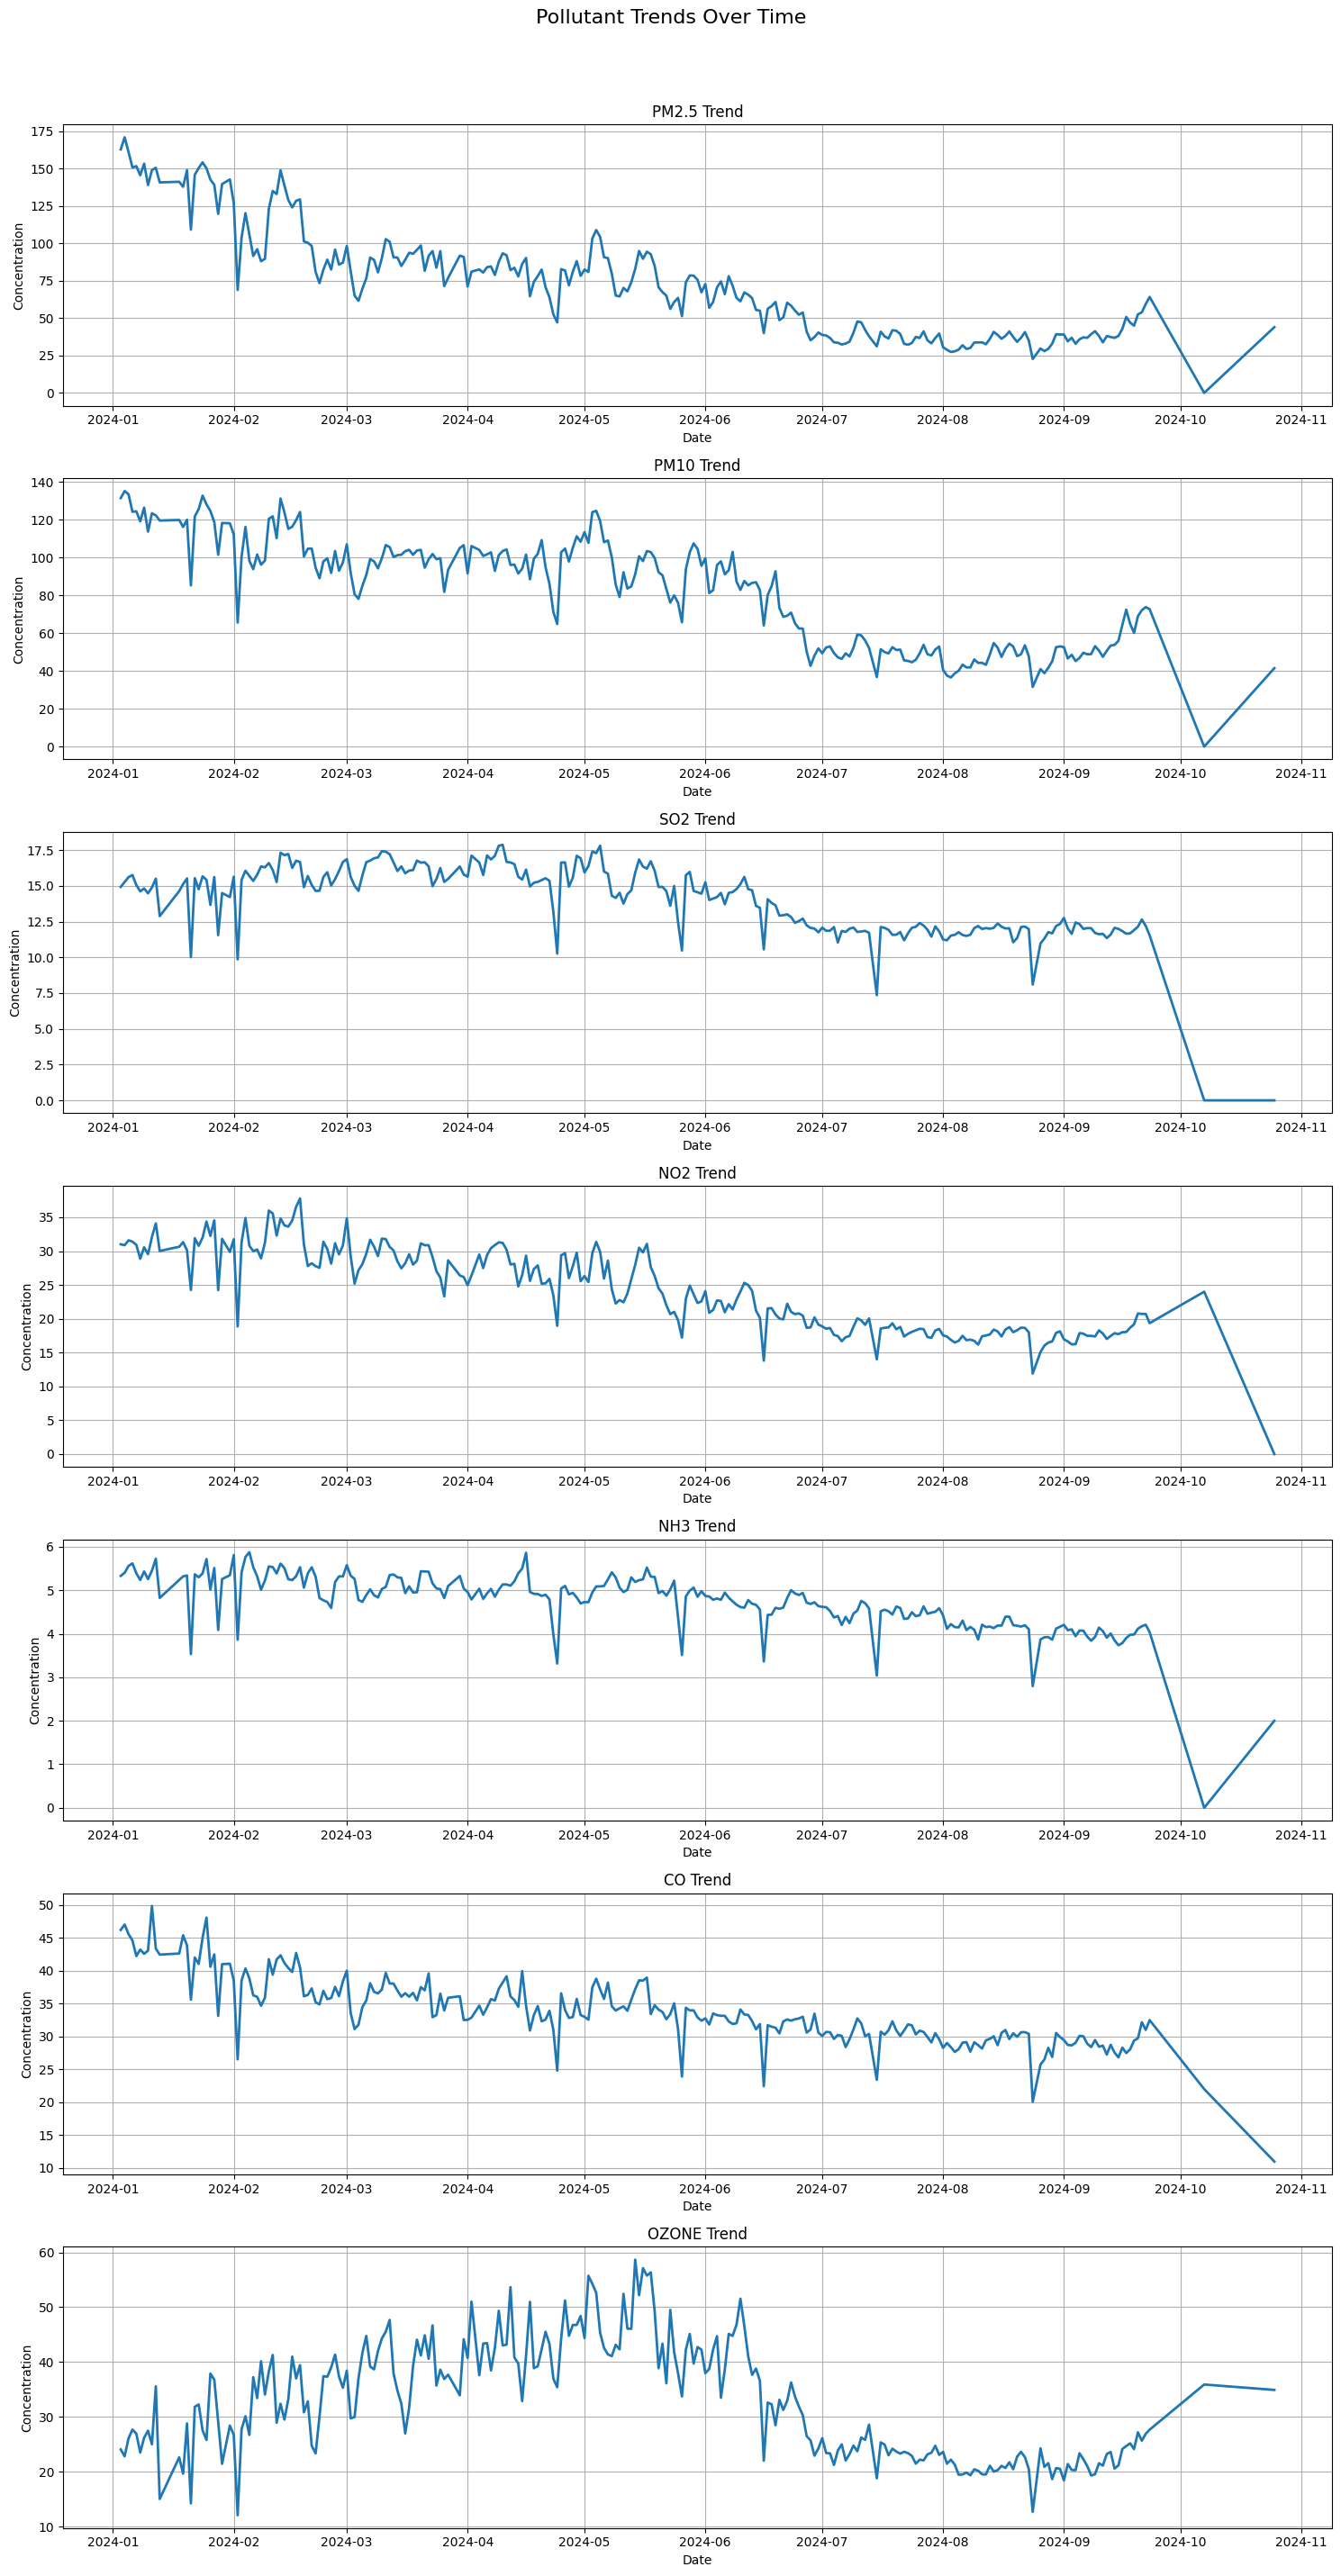

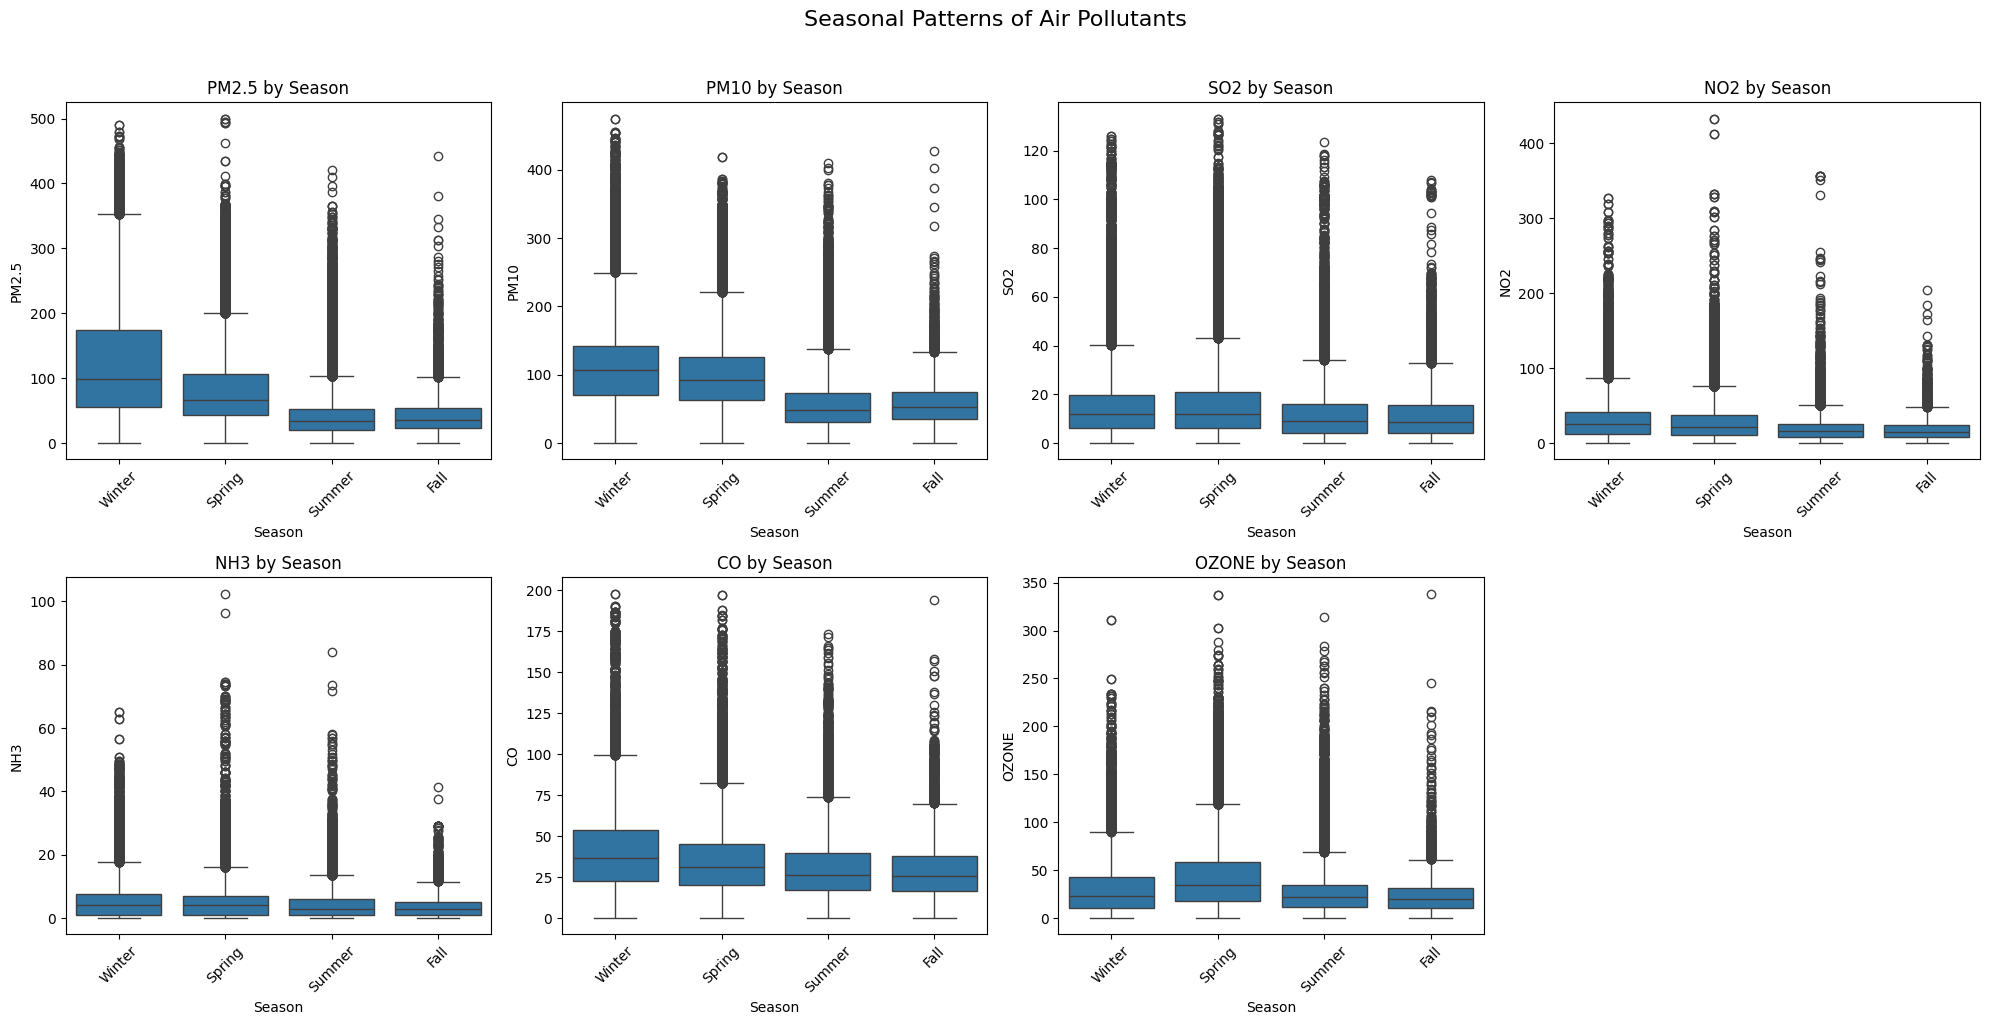

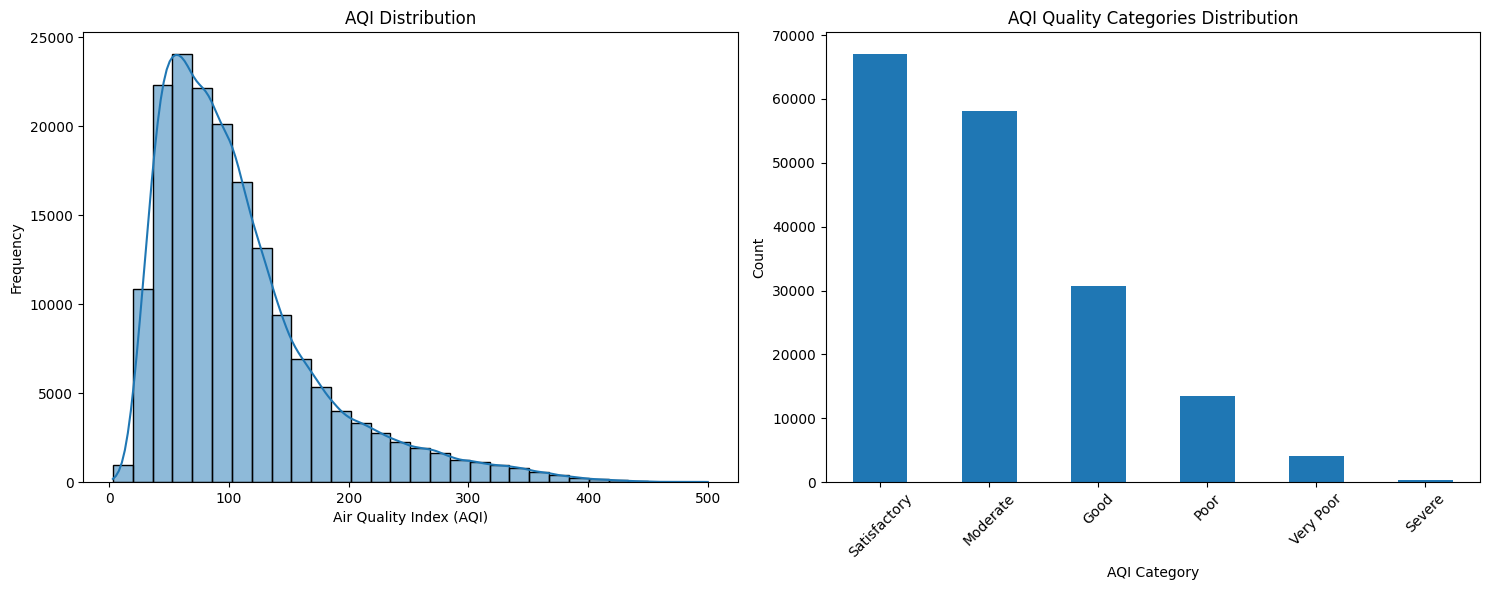


Pollutant Correlations:


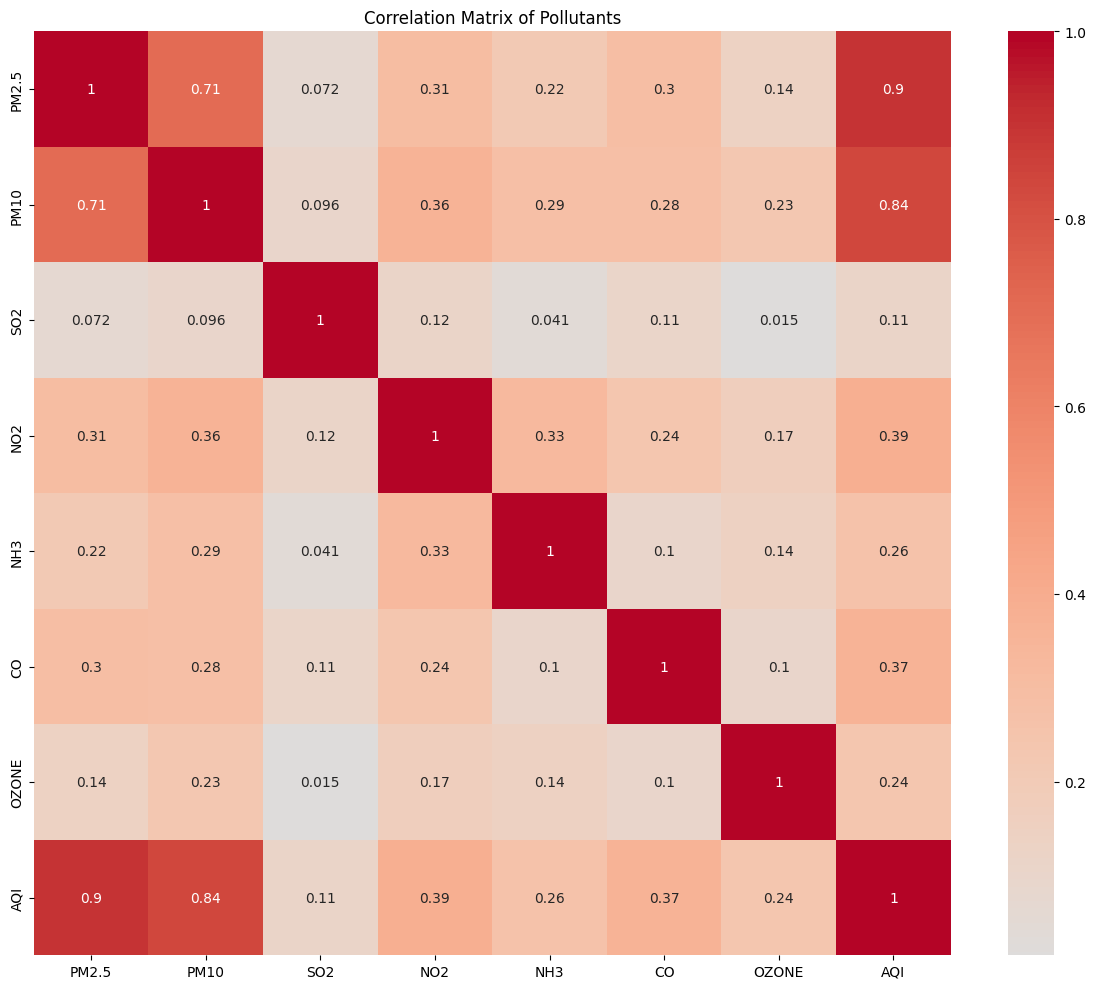

          PM2.5      PM10       SO2       NO2       NH3        CO     OZONE  \
PM2.5  1.000000  0.705061  0.072383  0.305669  0.215667  0.295585  0.137531   
PM10   0.705061  1.000000  0.095601  0.363260  0.287474  0.283589  0.228610   
SO2    0.072383  0.095601  1.000000  0.116273  0.040865  0.109022  0.014742   
NO2    0.305669  0.363260  0.116273  1.000000  0.329065  0.237955  0.169281   
NH3    0.215667  0.287474  0.040865  0.329065  1.000000  0.100215  0.144241   
CO     0.295585  0.283589  0.109022  0.237955  0.100215  1.000000  0.100363   
OZONE  0.137531  0.228610  0.014742  0.169281  0.144241  0.100363  1.000000   
AQI    0.897620  0.837519  0.113820  0.389262  0.259073  0.367417  0.239564   

            AQI  
PM2.5  0.897620  
PM10   0.837519  
SO2    0.113820  
NO2    0.389262  
NH3    0.259073  
CO     0.367417  
OZONE  0.239564  
AQI    1.000000  


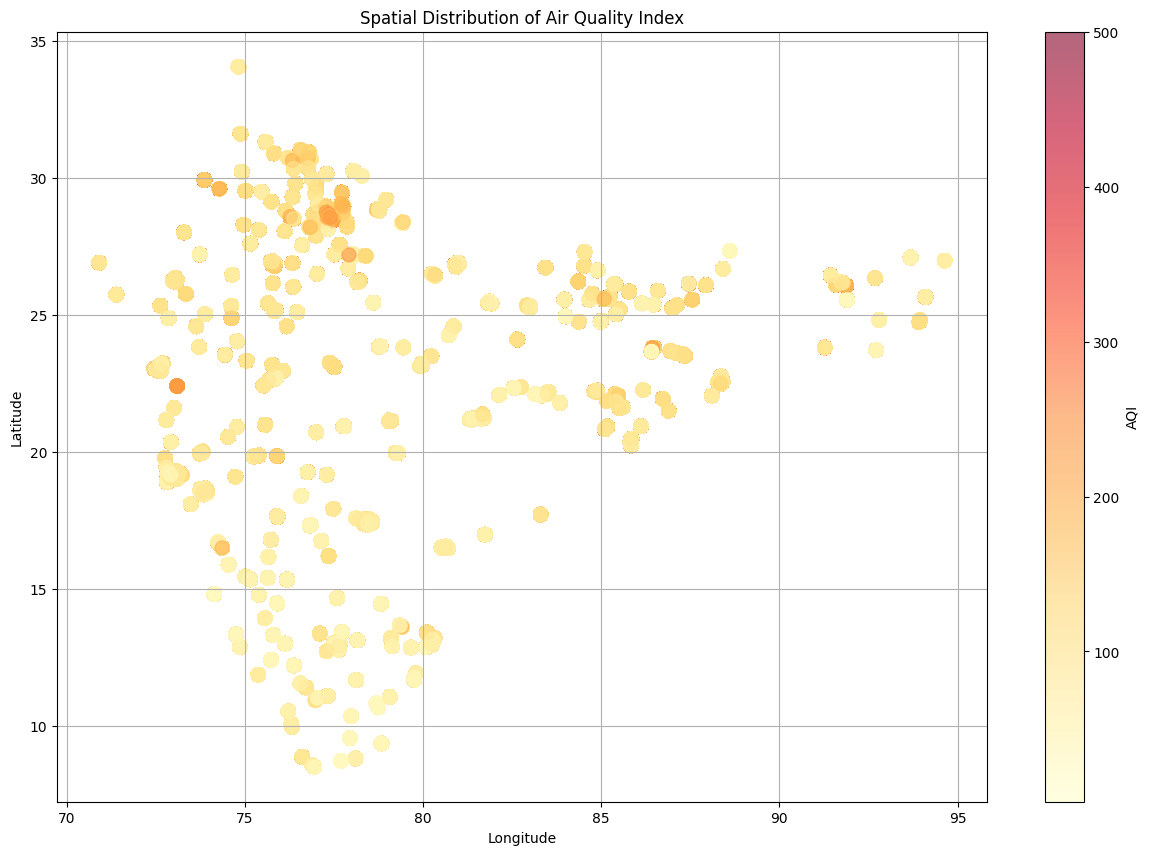


Monthly Report:
           AQI_Mean  AQI_Std  AQI_Min  AQI_Max Most_Common_Quality
January      165.60    95.66     3.00   490.00            Moderate
February     126.66    68.43    11.00   440.80            Moderate
March        112.12    52.05     9.56   386.80            Moderate
April        112.15    55.50     5.00   493.17            Moderate
May          114.72    66.53     6.00   500.00        Satisfactory
June          91.26    59.63     5.00   410.29        Satisfactory
July          60.96    33.01     7.20   420.00                Good
August        54.81    26.42     6.00   318.00                Good
September     65.12    34.25     5.00   442.75        Satisfactory
October       53.58    29.82    35.90    88.00                Good


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datetime import datetime
import calendar

class AirQualityAnalysis:
    def __init__(self, data):
        """Initialize with a DataFrame containing air quality data."""
        self.data = data.copy()
        self.data['Date'] = pd.to_datetime(self.data['Date'])
        self.data['Month'] = self.data['Date'].dt.month
        self.data['Season'] = self.data['Date'].dt.month.map(
            {1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 
             5: 'Spring', 6: 'Summer', 7: 'Summer', 8: 'Summer',
             9: 'Fall', 10: 'Fall', 11: 'Fall', 12: 'Winter'}
        )

    def generate_summary_statistics(self):
        """Generate summary statistics for all pollutants."""
        pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'NH3', 'CO', 'OZONE']
        summary = self.data[pollutants].describe()
        summary.loc['skewness'] = self.data[pollutants].skew()
        summary.loc['kurtosis'] = self.data[pollutants].kurtosis()
        return summary

    def plot_pollutant_trends(self, save_path=None):
        """Plot time series trends for each pollutant."""
        pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'NH3', 'CO', 'OZONE']
        
        fig, axes = plt.subplots(len(pollutants), 1, figsize=(15, 4*len(pollutants)))
        fig.suptitle('Pollutant Trends Over Time', fontsize=16, y=1.02)
        
        for idx, pollutant in enumerate(pollutants):
            daily_avg = self.data.groupby('Date')[pollutant].mean()
            
            axes[idx].plot(daily_avg.index, daily_avg.values, linewidth=2)
            axes[idx].set_title(f'{pollutant} Trend')
            axes[idx].set_xlabel('Date')
            axes[idx].set_ylabel('Concentration')
            axes[idx].grid(True)
            
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path)
        plt.show()

    def plot_seasonal_patterns(self, save_path=None):
        """Create boxplots showing seasonal patterns for each pollutant."""
        pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'NH3', 'CO', 'OZONE']
        
        fig, axes = plt.subplots(2, 4, figsize=(20, 10))
        fig.suptitle('Seasonal Patterns of Air Pollutants', fontsize=16, y=1.02)
        
        for idx, pollutant in enumerate(pollutants):
            row = idx // 4
            col = idx % 4
            
            sns.boxplot(data=self.data, x='Season', y=pollutant, ax=axes[row, col])
            axes[row, col].set_title(f'{pollutant} by Season')
            axes[row, col].tick_params(axis='x', rotation=45)
            
        # Remove empty subplot if any
        if len(pollutants) < 8:
            axes[1, -1].remove()
            
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path)
        plt.show()

    def plot_aqi_distribution(self, save_path=None):
        """Plot AQI distribution and quality categories."""
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        
        # AQI Distribution
        sns.histplot(data=self.data, x='AQI', bins=30, kde=True, ax=ax1)
        ax1.set_title('AQI Distribution')
        ax1.set_xlabel('Air Quality Index (AQI)')
        ax1.set_ylabel('Frequency')
        
        # AQI Quality Categories
        quality_counts = self.data['AQI_Quality'].value_counts()
        quality_counts.plot(kind='bar', ax=ax2)
        ax2.set_title('AQI Quality Categories Distribution')
        ax2.set_xlabel('AQI Category')
        ax2.set_ylabel('Count')
        ax2.tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path)
        plt.show()

    def calculate_correlations(self):
        """Calculate and visualize correlations between pollutants."""
        pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'NH3', 'CO', 'OZONE', 'AQI']
        correlation_matrix = self.data[pollutants].corr()
        
        plt.figure(figsize=(12, 10))
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
        plt.title('Correlation Matrix of Pollutants')
        plt.tight_layout()
        plt.show()
        
        return correlation_matrix

    def analyze_spatial_distribution(self):
        """Analyze and visualize spatial distribution of pollution."""
        plt.figure(figsize=(15, 10))
        
        scatter = plt.scatter(
            self.data['Longitude'], 
            self.data['Latitude'],
            c=self.data['AQI'],
            cmap='YlOrRd',
            s=100,
            alpha=0.6
        )
        
        plt.colorbar(scatter, label='AQI')
        plt.title('Spatial Distribution of Air Quality Index')
        plt.xlabel('Longitude')
        plt.ylabel('Latitude')
        plt.grid(True)
        plt.show()

    def generate_monthly_report(self, year=None):
        """Generate a monthly summary report of air quality metrics."""
        if year:
            data = self.data[self.data['Date'].dt.year == year]
        else:
            data = self.data
            
        monthly_stats = data.groupby('Month').agg({
            'AQI': ['mean', 'std', 'min', 'max'],
            'AQI_Quality': lambda x: x.mode()[0] if not x.empty else None
        }).round(2)
        
        monthly_stats.columns = ['AQI_Mean', 'AQI_Std', 'AQI_Min', 'AQI_Max', 'Most_Common_Quality']
        monthly_stats.index = [calendar.month_name[i] for i in monthly_stats.index]
        
        return monthly_stats

def main():
    # Example usage of the analysis module
    # Assuming you have your Platinum data loaded
    platinum_data = pd.read_csv('F:/Education/COLLEGE/PROGRAMING/Python/PROJECTS/PrachiNCUProject/Data/Platinum/pollutiondata_Final.csv')
    
    analyzer = AirQualityAnalysis(platinum_data)
    
    # Generate and print summary statistics
    print("\nSummary Statistics:")
    print(analyzer.generate_summary_statistics())
    
    # Generate visualizations
    analyzer.plot_pollutant_trends()
    analyzer.plot_seasonal_patterns()
    analyzer.plot_aqi_distribution()
    
    # Calculate and display correlations
    print("\nPollutant Correlations:")
    print(analyzer.calculate_correlations())
    
    # Analyze spatial distribution
    analyzer.analyze_spatial_distribution()
    
    # Generate monthly report
    print("\nMonthly Report:")
    print(analyzer.generate_monthly_report())

if __name__ == "__main__":
    main()